In [ ]:
# %% [markdown]
# # Re-Imputación con MICE - PISA 2022
# ## Imputación Multivariada por Ecuaciones Encadenadas
#
# **¿Cuándo usar este notebook?**
# - Detectaste problemas en la verificación post-imputación
# - Cambios >10% en medias de variables críticas
# - Cambios >0.15 en correlaciones importantes
# - Alta concentración de valores en medianas
# - Necesitas mayor rigor metodológico
#
# **Ventajas de MICE sobre mediana:**
# ✓ Preserva correlaciones entre variables
# ✓ Respeta la distribución multivariada
# ✓ Genera múltiples imputaciones (incertidumbre)
# ✓ Más apropiado para análisis estadísticos avanzados

# %%
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.ensemble import RandomForestRegressor
import warnings
warnings.filterwarnings('ignore')

print("✓ Librerías básicas cargadas")

# Verificar versión de scikit-learn
import sklearn
print(f"  Versión scikit-learn: {sklearn.__version__}")

# Configuración visual
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("husl")
plt.rcParams['figure.figsize'] = (14, 6)

✓ Librerías básicas cargadas
  Versión scikit-learn: 1.7.0


In [ ]:
# %% [markdown]
# ## 1. Cargar datos ORIGINALES (con valores faltantes)

# %%
# IMPORTANTE: Necesitas el dataset ANTES de cualquier imputación
# Si ya lo imputaste con mediana, intenta recuperar el original

try:
    # Opción A: Si guardaste el original
    df_original = pd.read_csv('../data_collection_peru_csv/data_merge/COLLECT_COMP_PERU.csv')
    print("✓ Dataset original cargado desde archivo")
except FileNotFoundError:
    print("⚠️ No se encontró el archivo original")
    print("\nOpciones:")
    print("1. Si tienes backup del dataset original → úsalo")
    print("2. Si solo tienes el imputado con mediana → puedes 're-contaminar' estratégicamente")
    print("3. Recomendado: Volver al merge inicial y empezar de nuevo")

    # Cargar el que tienes
    df_original = pd.read_csv('../data_ready/COLLECT_COMP_dataset_treated.csv')  # Ajusta el nombre
    print("\n⚠️ Trabajando con dataset ya procesado")

print(f"\nDimensiones: {df_original.shape}")
print(f"Datos faltantes totales: {df_original.isna().sum().sum():,}")

✓ Dataset original cargado desde archivo

Dimensiones: (6968, 7147)
Datos faltantes totales: 38,662,715



ANÁLISIS DE DATOS FALTANTES

📊 Resumen General:
   Total de celdas: 49,800,296
   Celdas faltantes: 38,662,715
   Porcentaje faltante: 77.64%

📋 Top 20 variables con más datos faltantes:
  Variable  N_Missing  Pct_Missing
DT450Q03C2       6968        100.0
 DT450Q03C       6968        100.0
 DT450Q02C       6968        100.0
  T560Q02S       6968        100.0
  T560Q01S       6968        100.0
 DT300Q02C       6968        100.0
  ALLACTIV       6968        100.0
WBEnd01_TT       6968        100.0
  WB178_TT       6968        100.0
  WB177_TT       6968        100.0
  WB176_TT       6968        100.0
  WB173_TT       6968        100.0
  WB172_TT       6968        100.0
  WB171_TT       6968        100.0
  WB168_TT       6968        100.0
  WB167_TT       6968        100.0
  WB166_TT       6968        100.0
  WB165_TT       6968        100.0
  WB164_TT       6968        100.0
  WB163_TT       6968        100.0

✓ 589 variables sin datos faltantes


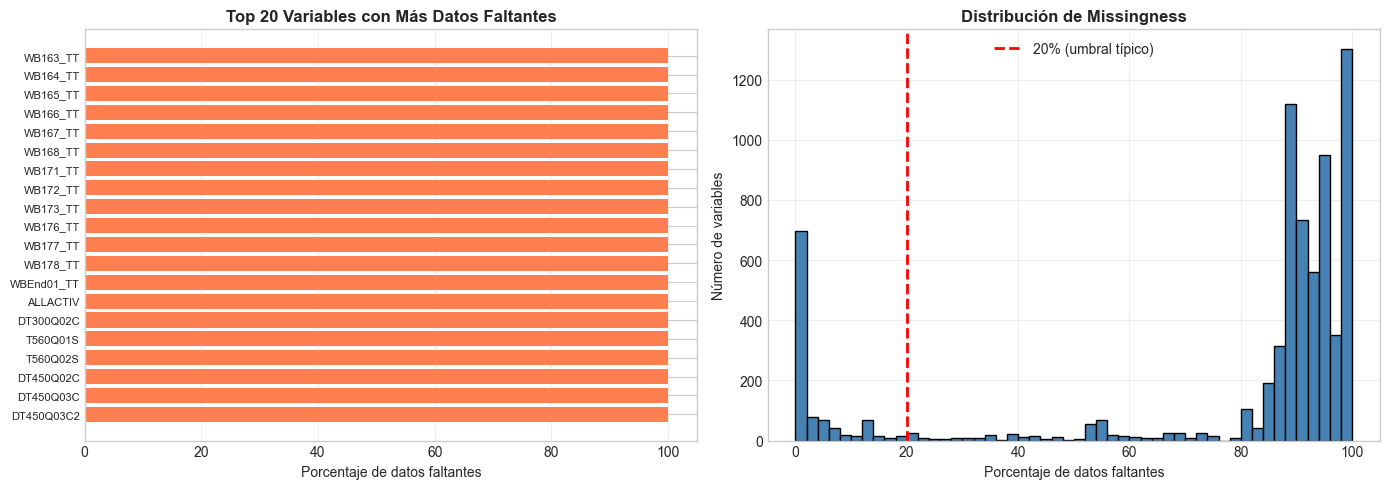

In [ ]:
# %% [markdown]
# ## 2. Análisis pre-imputación

# %%
def analizar_missing_data(df):
    """
    Analiza el patrón de datos faltantes
    """
    print("\n" + "="*80)
    print("ANÁLISIS DE DATOS FALTANTES")
    print("="*80)

    # Resumen general
    total_cells = df.shape[0] * df.shape[1]
    missing_cells = df.isna().sum().sum()
    pct_missing = missing_cells / total_cells * 100

    print(f"\n📊 Resumen General:")
    print(f"   Total de celdas: {total_cells:,}")
    print(f"   Celdas faltantes: {missing_cells:,}")
    print(f"   Porcentaje faltante: {pct_missing:.2f}%")

    # Por variable
    missing_por_var = pd.DataFrame({
        'Variable': df.columns,
        'N_Missing': df.isna().sum(),
        'Pct_Missing': (df.isna().sum() / len(df) * 100).round(2)
    }).sort_values('Pct_Missing', ascending=False)

    # Top 20 con más faltantes
    print(f"\n📋 Top 20 variables con más datos faltantes:")
    print(missing_por_var.head(20).to_string(index=False))

    # Variables completamente llenas
    vars_completas = missing_por_var[missing_por_var['N_Missing'] == 0]
    print(f"\n✓ {len(vars_completas)} variables sin datos faltantes")

    # Visualización
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # Gráfico 1: Top 20 variables
    top_20 = missing_por_var.head(20)
    axes[0].barh(range(len(top_20)), top_20['Pct_Missing'], color='coral')
    axes[0].set_yticks(range(len(top_20)))
    axes[0].set_yticklabels(top_20['Variable'], fontsize=8)
    axes[0].set_xlabel('Porcentaje de datos faltantes')
    axes[0].set_title('Top 20 Variables con Más Datos Faltantes', fontweight='bold')
    axes[0].grid(axis='x', alpha=0.3)

    # Gráfico 2: Distribución de missingness
    axes[1].hist(missing_por_var['Pct_Missing'], bins=50, color='steelblue', edgecolor='black')
    axes[1].axvline(20, color='red', linestyle='--', linewidth=2, label='20% (umbral típico)')
    axes[1].set_xlabel('Porcentaje de datos faltantes')
    axes[1].set_ylabel('Número de variables')
    axes[1].set_title('Distribución de Missingness', fontweight='bold')
    axes[1].legend()
    axes[1].grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

    return missing_por_var

missing_info = analizar_missing_data(df_original)

In [ ]:
# %% [markdown]
# ## 3. Selección de variables para imputar

# %%
# ESTRATEGIA: No imputes TODO, solo variables importantes

def seleccionar_variables_imputacion(df, missing_info, umbral_max=50,
                                     variables_criticas=None):
    """
    Selecciona qué variables deben imputarse
    """
    print("\n" + "="*80)
    print("SELECCIÓN DE VARIABLES PARA IMPUTACIÓN")
    print("="*80)

    # Filtrar variables según criterios
    candidatas = missing_info[
        (missing_info['Pct_Missing'] > 0) &  # Tienen missing
        (missing_info['Pct_Missing'] <= umbral_max)  # No exceden umbral
    ].copy()

    print(f"\n📋 Variables candidatas: {len(candidatas)}")
    print(f"   (tienen missing pero <{umbral_max}%)")

    # Si hay variables críticas definidas, priorizarlas
    if variables_criticas:
        candidatas['Es_Critica'] = candidatas['Variable'].isin(variables_criticas)
        print(f"\n✓ Variables críticas en candidatas: {candidatas['Es_Critica'].sum()}")

    # Identificar tipos
    numericas = df.select_dtypes(include=[np.number]).columns.tolist()
    categoricas = df.select_dtypes(include=['object', 'category']).columns.tolist()

    candidatas['Tipo'] = candidatas['Variable'].apply(
        lambda x: 'Numérica' if x in numericas else 'Categórica'
    )

    print("\n📊 Por tipo:")
    print(candidatas['Tipo'].value_counts())

    # Separar por tipo
    vars_num_imputar = candidatas[candidatas['Tipo'] == 'Numérica']['Variable'].tolist()
    vars_cat_imputar = candidatas[candidatas['Tipo'] == 'Categórica']['Variable'].tolist()

    return vars_num_imputar, vars_cat_imputar, candidatas

# Definir variables críticas (PERSONALIZAR CON TUS VARIABLES)
# variables_criticas = [
#     # Agrega aquí las que identificaste como críticas
#     # Ejemplo:
#     # 'PV1MATH', 'PV1READ', 'PV1SCIE',
#     # 'ESCS', 'HOMEPOS', 'WEALTH',
#     # 'ST004D01T',
# ]

variables_criticas = [
    # Nivel 1: Outcome
    'PV9MATH',        # Rendimiento en matemáticas (valor plausible)
    'PV5READ',        # Rendimiento en lectura

    # Nivel 2: Predictores principales / socioeconómicos
    'ESCS',           # Estatus socioeconómico general
    'HOMEPOS',        # Bienes del hogar — riqueza material
    'HISEI',          # Ocupación de los padres

    # Controles estándar
    'ST004D01T',      # Género
    'AGE',            # Edad
    'IMMIG',          # Status migratorio
    'LANGN',          # Idioma nativo del estudiante respecto al idioma de prueba

    # Predictores lingüísticos/contexto de idioma
    'LANGTEST_COG',   # Habilidad cognitiva del idioma / test de idioma
    'LANGTEST_PAQ',   # Quizás percepción de habilidad lingüística

    # (Opcional: descomponer ESCS si interesan componentes específicos)
    # 'HOMEPOS', 'HISEI' ya incluidos
]

# Buscar automáticamente algunas variables críticas comunes
for patron in ['PV1MATH', 'PV1READ', 'ESCS', 'HOMEPOS']:
    matches = [col for col in df_original.columns if patron in col.upper()]
    variables_criticas.extend(matches)

variables_criticas = list(set(variables_criticas))  # Eliminar duplicados

print(f"Variables críticas identificadas: {len(variables_criticas)}")
if len(variables_criticas) > 0:
    print("Primeras 10:", variables_criticas[:10])

# Seleccionar variables
vars_num_imputar, vars_cat_imputar, candidatas = seleccionar_variables_imputacion(
    df_original, missing_info, umbral_max=50, variables_criticas=variables_criticas
)

print(f"\n✅ Resumen de selección:")
print(f"   Variables numéricas a imputar: {len(vars_num_imputar)}")
print(f"   Variables categóricas a imputar: {len(vars_cat_imputar)}")

Variables críticas identificadas: 13
Primeras 10: ['HISEI', 'LANGTEST_COG', 'LANGTEST_PAQ', 'PV1MATH', 'ESCS', 'PV5READ', 'ST004D01T', 'AGE', 'IMMIG', 'LANGN']

SELECCIÓN DE VARIABLES PARA IMPUTACIÓN

📋 Variables candidatas: 595
   (tienen missing pero <50%)

✓ Variables críticas en candidatas: 4

📊 Por tipo:
Tipo
Categórica    390
Numérica      205
Name: count, dtype: int64

✅ Resumen de selección:
   Variables numéricas a imputar: 205
   Variables categóricas a imputar: 390


In [ ]:
# %% [markdown]
# ## 4. Preparación del dataset para MICE

# %%
def preparar_datos_mice(df, vars_numericas, max_vars=50):
    """
    Prepara el dataset para MICE
    MICE es computacionalmente costoso, limitamos variables
    """
    print("\n" + "="*80)
    print("PREPARACIÓN DE DATOS PARA MICE")
    print("="*80)

    # Limitar número de variables si es muy grande
    if len(vars_numericas) > max_vars:
        print(f"\n⚠️ {len(vars_numericas)} variables es mucho para MICE")
        print(f"   Limitando a {max_vars} más importantes")

        # Priorizar: 1) Críticas, 2) Menos faltantes, 3) Mayor varianza
        prioridad = []
        for var in vars_numericas[:max_vars]:
            pct_missing = df[var].isna().sum() / len(df) * 100
            varianza = df[var].var() if df[var].var() is not None else 0
            prioridad.append((var, pct_missing, varianza))

        # Ordenar por menos faltantes y mayor varianza
        prioridad.sort(key=lambda x: (x[1], -x[2]))
        vars_numericas = [x[0] for x in prioridad[:max_vars]]

    # Crear subset de datos
    df_mice = df[vars_numericas].copy()

    print(f"\n✓ Dataset preparado:")
    print(f"   Filas: {len(df_mice):,}")
    print(f"   Variables: {len(df_mice.columns)}")
    print(f"   Celdas totales: {len(df_mice) * len(df_mice.columns):,}")
    print(f"   Celdas faltantes: {df_mice.isna().sum().sum():,}")
    print(f"   % faltante: {df_mice.isna().sum().sum() / (len(df_mice) * len(df_mice.columns)) * 100:.2f}%")

    return df_mice

df_para_mice = preparar_datos_mice(df_original, vars_num_imputar, max_vars=50)
# %%


PREPARACIÓN DE DATOS PARA MICE

⚠️ 205 variables es mucho para MICE
   Limitando a 50 más importantes

✓ Dataset preparado:
   Filas: 6,968
   Variables: 50
   Celdas totales: 348,400
   Celdas faltantes: 109,420
   % faltante: 31.41%


In [6]:
# %% [markdown]
# ## 5. Configuración de MICE

# %%
print("\n" + "="*80)
print("CONFIGURACIÓN DE MICE")
print("="*80)

print("""
MICE (Multivariate Imputation by Chained Equations):

1. Para cada variable con missing:
   - La trata como dependiente
   - Usa las demás como predictores
   - Ajusta un modelo de regresión
   - Imputa los valores faltantes

2. Itera el proceso varias veces hasta convergencia

3. Puede generar múltiples imputaciones para capturar incertidumbre

Parámetros importantes:
- max_iter: Número de iteraciones (5-10 típico)
- random_state: Semilla para reproducibilidad
- estimator: Modelo base (LinearRegression, RandomForest, etc.)
""")

# Configurar MICE con diferentes estimadores

print("\n🔧 Opciones de estimador:")
print("1. LinearRegression (rápido, asume linealidad)")
print("2. RandomForestRegressor (lento, captura no-linealidad)")
print("3. BayesianRidge (balance, maneja colinealidad)")

print("\nUsaremos RandomForest para mejor calidad (más lento)")

# Crear imputador
mice_imputer = IterativeImputer(
    estimator=RandomForestRegressor(n_estimators=10, max_depth=5, random_state=42),
    max_iter=10,  # Número de ciclos
    random_state=42,  # Reproducibilidad
    verbose=2  # Mostrar progreso
)

print("\n✓ Imputador MICE configurado")


CONFIGURACIÓN DE MICE

MICE (Multivariate Imputation by Chained Equations):

1. Para cada variable con missing:
   - La trata como dependiente
   - Usa las demás como predictores
   - Ajusta un modelo de regresión
   - Imputa los valores faltantes

2. Itera el proceso varias veces hasta convergencia

3. Puede generar múltiples imputaciones para capturar incertidumbre

Parámetros importantes:
- max_iter: Número de iteraciones (5-10 típico)
- random_state: Semilla para reproducibilidad
- estimator: Modelo base (LinearRegression, RandomForest, etc.)


🔧 Opciones de estimador:
1. LinearRegression (rápido, asume linealidad)
2. RandomForestRegressor (lento, captura no-linealidad)
3. BayesianRidge (balance, maneja colinealidad)

Usaremos RandomForest para mejor calidad (más lento)

✓ Imputador MICE configurado


In [ ]:
# %% [markdown]
# ## 6. Ejecutar MICE (¡ESTO PUEDE TARDAR!)

# %%
import time

print("\n" + "="*80)
print("EJECUTANDO MICE")
print("="*80)

print("\n⏱️ Estimación de tiempo:")
n_vars = len(df_para_mice.columns)
n_rows = len(df_para_mice)
tiempo_estimado = (n_vars * n_rows) / 50000  # Aproximación
print(f"   Variables: {n_vars}")
print(f"   Observaciones: {n_rows:,}")
print(f"   Tiempo estimado: {tiempo_estimado:.1f} minutos")

print("\n⚠️ ADVERTENCIA: MICE puede tardar mucho con datasets grandes")
print("   Si tarda >30 minutos, considera:")
print("   - Reducir max_vars en la preparación")
print("   - Usar muestra aleatoria del dataset")
print("   - Usar estimador más simple (LinearRegression)")

respuesta = input("\n¿Continuar con la imputación? (s/n): ")

if respuesta.lower() == 's':
    print("\n🚀 Iniciando imputación MICE...")
    inicio = time.time()

    # Ajustar y transformar
    df_imputado_mice = pd.DataFrame(
        mice_imputer.fit_transform(df_para_mice),
        columns=df_para_mice.columns,
        index=df_para_mice.index
    )

    tiempo_total = time.time() - inicio
    print(f"\n✅ Imputación completada en {tiempo_total/60:.2f} minutos")

    # Verificar que no haya NaN
    nan_restantes = df_imputado_mice.isna().sum().sum()
    print(f"   NaN restantes: {nan_restantes}")

    if nan_restantes > 0:
        print("\n⚠️ Aún hay valores faltantes")
        print("   Posibles causas:")
        print("   - Variables con 100% missing en el subset")
        print("   - Problemas de convergencia")
        print("   Aplicando imputación de backup con mediana...")

        from sklearn.impute import SimpleImputer
        backup_imputer = SimpleImputer(strategy='median')
        df_imputado_mice = pd.DataFrame(
            backup_imputer.fit_transform(df_imputado_mice),
            columns=df_imputado_mice.columns,
            index=df_imputado_mice.index
        )
else:
    print("\n⚠️ Imputación cancelada")
    print("   Considera ejecutar con un subset más pequeño primero")
    # Crear dummy para que el notebook siga funcionando
    df_imputado_mice = df_para_mice.copy()


EJECUTANDO MICE

⏱️ Estimación de tiempo:
   Variables: 50
   Observaciones: 6,968
   Tiempo estimado: 7.0 minutos

⚠️ ADVERTENCIA: MICE puede tardar mucho con datasets grandes
   Si tarda >30 minutos, considera:
   - Reducir max_vars en la preparación
   - Usar muestra aleatoria del dataset
   - Usar estimador más simple (LinearRegression)

🚀 Iniciando imputación MICE...
[IterativeImputer] Completing matrix with shape (6968, 50)
[IterativeImputer] Ending imputation round 1/10, elapsed time 57.93
[IterativeImputer] Change: 3128947.6633832166, scaled tolerance: 3920.625 
[IterativeImputer] Ending imputation round 2/10, elapsed time 149.62
[IterativeImputer] Change: 2951161.04465005, scaled tolerance: 3920.625 
[IterativeImputer] Ending imputation round 3/10, elapsed time 219.53
[IterativeImputer] Change: 1581178.8538870628, scaled tolerance: 3920.625 
[IterativeImputer] Ending imputation round 4/10, elapsed time 273.38
[IterativeImputer] Change: 3490955.7761893617, scaled tolerance: 39

In [ ]:
# %% [markdown]
# ## 7. Comparación: Mediana vs MICE

# %%
def comparar_metodos_imputacion(df_original, df_mice, variable):
    """
    Compara imputación por mediana vs MICE
    """
    if variable not in df_original.columns or variable not in df_mice.columns:
        print(f"⚠️ Variable {variable} no encontrada")
        return

    # Datos originales (sin NaN)
    original_clean = df_original[variable].dropna()

    # Imputación por mediana (para comparar)
    df_mediana = df_original[[variable]].copy()
    mediana = df_mediana[variable].median()
    df_mediana[variable].fillna(mediana, inplace=True)

    # Datos MICE
    mice_data = df_mice[variable]

    # Identificar valores imputados
    mask_imputado = df_original[variable].isna()
    valores_imputados_mediana = df_mediana.loc[mask_imputado, variable]
    valores_imputados_mice = df_mice.loc[mask_imputado, variable]

    # Visualización
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))

    # 1. Histogramas comparativos
    axes[0, 0].hist(original_clean, bins=50, alpha=0.5, label='Original',
                    color='blue', density=True)
    axes[0, 0].hist(df_mediana[variable], bins=50, alpha=0.5, label='Mediana',
                    color='red', density=True)
    axes[0, 0].hist(mice_data, bins=50, alpha=0.5, label='MICE',
                    color='green', density=True)
    axes[0, 0].set_title(f'Distribuciones Completas: {variable}')
    axes[0, 0].legend()
    axes[0, 0].grid(alpha=0.3)

    # 2. Solo valores imputados
    if len(valores_imputados_mediana) > 0:
        axes[0, 1].hist(valores_imputados_mediana, bins=30, alpha=0.6,
                       label='Mediana', color='red', density=True)
        axes[0, 1].hist(valores_imputados_mice, bins=30, alpha=0.6,
                       label='MICE', color='green', density=True)
        axes[0, 1].set_title('Solo Valores Imputados')
        axes[0, 1].legend()
        axes[0, 1].grid(alpha=0.3)

    # 3. Q-Q plots
    from scipy import stats
    stats.probplot(df_mediana[variable], dist="norm", plot=axes[1, 0])
    axes[1, 0].set_title('Q-Q Plot: Mediana')
    axes[1, 0].grid(alpha=0.3)

    stats.probplot(mice_data, dist="norm", plot=axes[1, 1])
    axes[1, 1].set_title('Q-Q Plot: MICE')
    axes[1, 1].grid(alpha=0.3)

    plt.suptitle(f'Comparación Mediana vs MICE: {variable}',
                fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()

    # Estadísticas comparativas
    print(f"\n{'='*70}")
    print(f"COMPARACIÓN ESTADÍSTICA: {variable}")
    print(f"{'='*70}")

    stats_comp = pd.DataFrame({
        'Métrica': ['N', 'Media', 'Mediana', 'DE', 'Min', 'Max', 'Asimetría', 'Curtosis'],
        'Original': [
            len(original_clean),
            original_clean.mean(),
            original_clean.median(),
            original_clean.std(),
            original_clean.min(),
            original_clean.max(),
            original_clean.skew(),
            original_clean.kurtosis()
        ],
        'Mediana': [
            len(df_mediana),
            df_mediana[variable].mean(),
            df_mediana[variable].median(),
            df_mediana[variable].std(),
            df_mediana[variable].min(),
            df_mediana[variable].max(),
            df_mediana[variable].skew(),
            df_mediana[variable].kurtosis()
        ],
        'MICE': [
            len(mice_data),
            mice_data.mean(),
            mice_data.median(),
            mice_data.std(),
            mice_data.min(),
            mice_data.max(),
            mice_data.skew(),
            mice_data.kurtosis()
        ]
    })

    print(stats_comp.round(3).to_string(index=False))

    # Calcular diferencias
    print(f"\n📊 Diferencia con Original:")
    print(f"   Mediana - Media: {abs(df_mediana[variable].mean() - original_clean.mean()):.3f}")
    print(f"   MICE - Media: {abs(mice_data.mean() - original_clean.mean()):.3f}")
    print(f"   Mediana - DE: {abs(df_mediana[variable].std() - original_clean.std()):.3f}")
    print(f"   MICE - DE: {abs(mice_data.std() - original_clean.std()):.3f}")

    # Determinar ganador
    diff_media_mediana = abs(df_mediana[variable].mean() - original_clean.mean())
    diff_media_mice = abs(mice_data.mean() - original_clean.mean())
    diff_de_mediana = abs(df_mediana[variable].std() - original_clean.std())
    diff_de_mice = abs(mice_data.std() - original_clean.std())

    print(f"\n🏆 MEJOR MÉTODO:")
    if diff_media_mice < diff_media_mediana and diff_de_mice < diff_de_mediana:
        print("   ✅ MICE preserva mejor la distribución original")
    elif diff_media_mediana < diff_media_mice and diff_de_mediana < diff_de_mice:
        print("   ✅ Mediana preserva mejor la distribución original")
    else:
        print("   ⚪ Ambos métodos tienen ventajas similares")

# Comparar para variables críticas
if 'df_imputado_mice' in locals() and len(variables_criticas) > 0:
    print("\n" + "="*80)
    print("COMPARACIÓN MEDIANA VS MICE - VARIABLES CRÍTICAS")
    print("="*80)

    for var in variables_criticas[:3]:  # Primeras 3 para no saturar
        if var in df_imputado_mice.columns:
            comparar_metodos_imputacion(df_para_mice, df_imputado_mice, var)


COMPARACIÓN MEDIANA VS MICE - VARIABLES CRÍTICAS


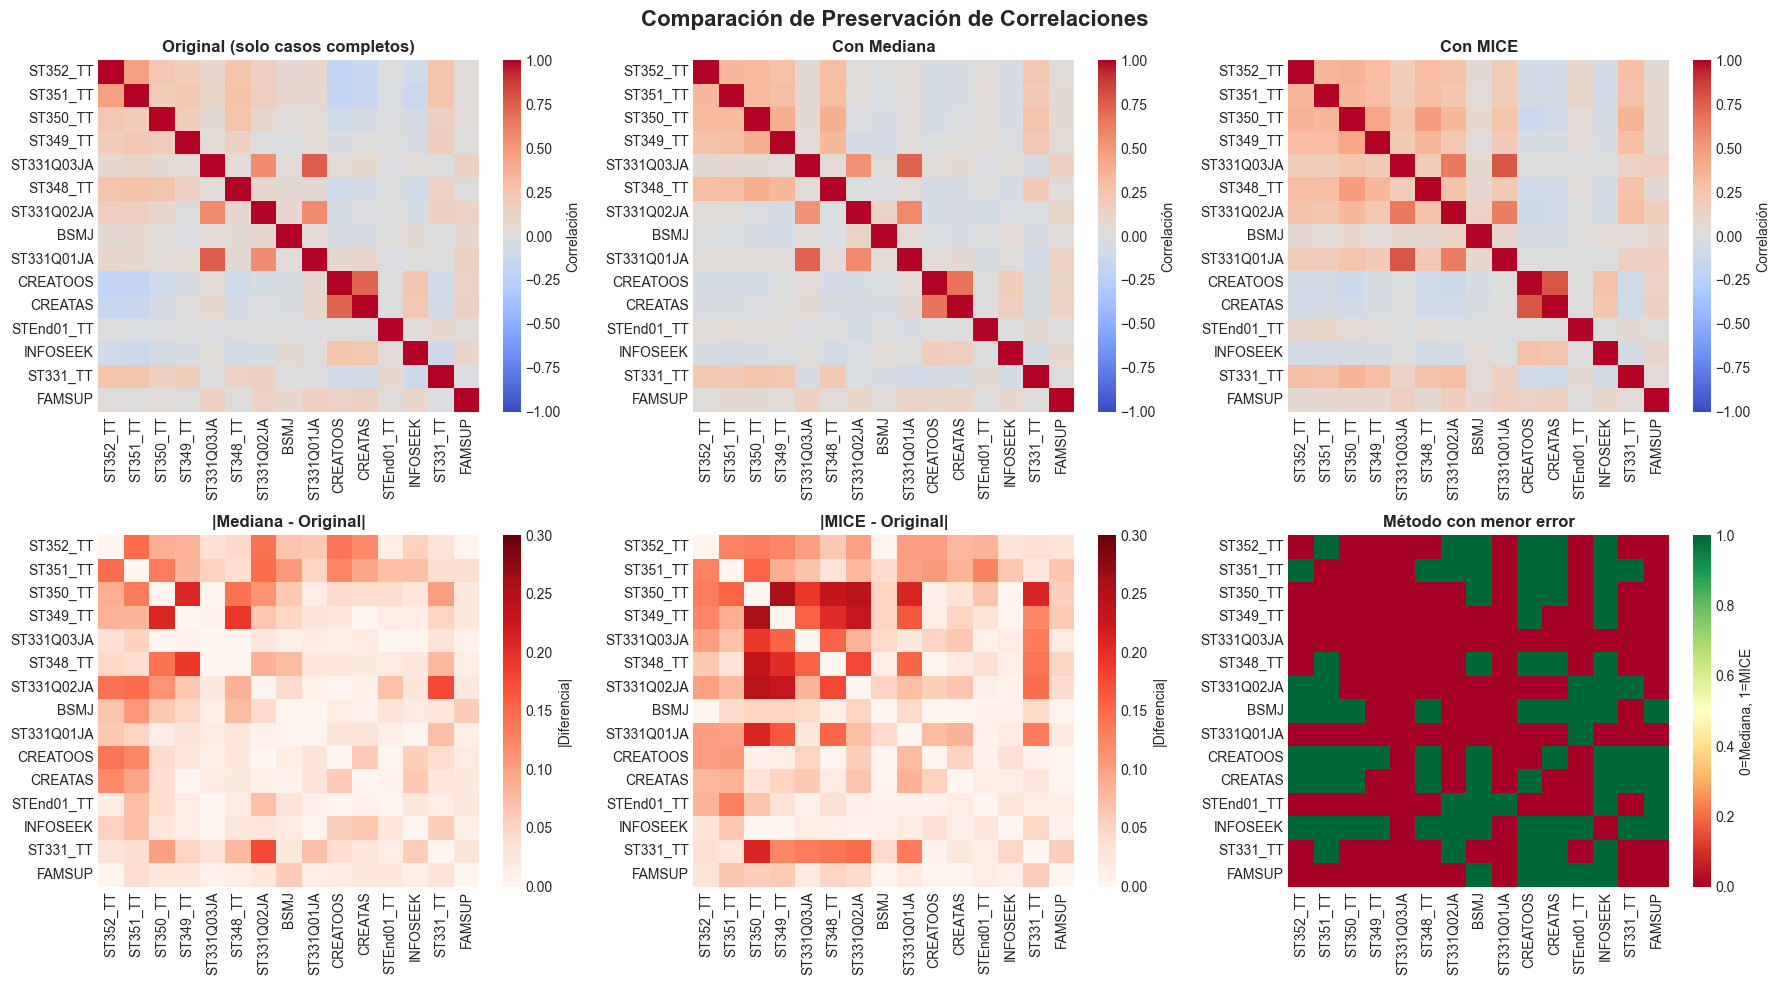


PRESERVACIÓN DE CORRELACIONES

Diferencia media absoluta con original:
   Mediana: 0.0476
   MICE: 0.0687

Diferencia máxima:
   Mediana: 0.2086
   MICE: 0.2574

Porcentaje de correlaciones con |error| < 0.05:
   Mediana: 63.8%
   MICE: 50.5%

🏆 Mediana preserva mejor las correlaciones originales


In [ ]:
# %% [markdown]
# ## 8. Comparación de correlaciones

# %%
def comparar_correlaciones_metodos(df_original, df_mice, variables):
    """
    Compara cómo cada método preserva correlaciones
    """
    # Seleccionar variables comunes
    vars_comunes = [v for v in variables if v in df_original.columns and v in df_mice.columns]
    vars_comunes = vars_comunes[:15]  # Limitar para visualización

    if len(vars_comunes) < 2:
        print("⚠️ Insuficientes variables para comparar correlaciones")
        return

    # Correlaciones originales (solo casos completos)
    df_completo = df_original[vars_comunes].dropna()
    corr_original = df_completo.corr()

    # Correlaciones con mediana
    df_mediana = df_original[vars_comunes].copy()
    for col in df_mediana.columns:
        df_mediana[col].fillna(df_mediana[col].median(), inplace=True)
    corr_mediana = df_mediana.corr()

    # Correlaciones con MICE
    corr_mice = df_mice[vars_comunes].corr()

    # Diferencias
    diff_mediana = abs(corr_mediana - corr_original)
    diff_mice = abs(corr_mice - corr_original)

    # Visualización
    fig, axes = plt.subplots(2, 3, figsize=(18, 10))

    # Fila 1: Matrices de correlación
    sns.heatmap(corr_original, annot=False, cmap='coolwarm', center=0,
                vmin=-1, vmax=1, ax=axes[0, 0], cbar_kws={'label': 'Correlación'})
    axes[0, 0].set_title('Original (solo casos completos)', fontweight='bold')

    sns.heatmap(corr_mediana, annot=False, cmap='coolwarm', center=0,
                vmin=-1, vmax=1, ax=axes[0, 1], cbar_kws={'label': 'Correlación'})
    axes[0, 1].set_title('Con Mediana', fontweight='bold')

    sns.heatmap(corr_mice, annot=False, cmap='coolwarm', center=0,
                vmin=-1, vmax=1, ax=axes[0, 2], cbar_kws={'label': 'Correlación'})
    axes[0, 2].set_title('Con MICE', fontweight='bold')

    # Fila 2: Diferencias con original
    sns.heatmap(diff_mediana, annot=False, cmap='Reds', vmin=0, vmax=0.3,
                ax=axes[1, 0], cbar_kws={'label': '|Diferencia|'})
    axes[1, 0].set_title('|Mediana - Original|', fontweight='bold')

    sns.heatmap(diff_mice, annot=False, cmap='Reds', vmin=0, vmax=0.3,
                ax=axes[1, 1], cbar_kws={'label': '|Diferencia|'})
    axes[1, 1].set_title('|MICE - Original|', fontweight='bold')

    # Comparación directa
    mejor_metodo = (diff_mice < diff_mediana).astype(int)
    sns.heatmap(mejor_metodo, annot=False, cmap='RdYlGn', vmin=0, vmax=1,
                ax=axes[1, 2], cbar_kws={'label': '0=Mediana, 1=MICE'})
    axes[1, 2].set_title('Método con menor error', fontweight='bold')

    plt.suptitle('Comparación de Preservación de Correlaciones',
                fontsize=16, fontweight='bold')
    plt.tight_layout()
    plt.show()

    # Estadísticas
    print("\n" + "="*70)
    print("PRESERVACIÓN DE CORRELACIONES")
    print("="*70)

    # Extraer triángulo superior (sin diagonal)
    mask = np.triu(np.ones_like(corr_original), k=1).astype(bool)

    diff_mediana_values = diff_mediana.where(mask).stack().values
    diff_mice_values = diff_mice.where(mask).stack().values

    print(f"\nDiferencia media absoluta con original:")
    print(f"   Mediana: {diff_mediana_values.mean():.4f}")
    print(f"   MICE: {diff_mice_values.mean():.4f}")

    print(f"\nDiferencia máxima:")
    print(f"   Mediana: {diff_mediana_values.max():.4f}")
    print(f"   MICE: {diff_mice_values.max():.4f}")

    print(f"\nPorcentaje de correlaciones con |error| < 0.05:")
    print(f"   Mediana: {(diff_mediana_values < 0.05).mean() * 100:.1f}%")
    print(f"   MICE: {(diff_mice_values < 0.05).mean() * 100:.1f}%")

    # Ganador
    if diff_mice_values.mean() < diff_mediana_values.mean():
        print(f"\n🏆 MICE preserva mejor las correlaciones originales")
    else:
        print(f"\n🏆 Mediana preserva mejor las correlaciones originales")

if 'df_imputado_mice' in locals():
    comparar_correlaciones_metodos(df_para_mice, df_imputado_mice, vars_num_imputar)

In [ ]:
# %% [markdown]
# ## 8.5. DECISIÓN AUTOMÁTICA: ¿Usar Mediana o MICE?

# %%
def decidir_mejor_metodo(df_original, df_mice, vars_numericas, umbral_mejora=0.02):
    """
    Decide automáticamente si MICE es significativamente mejor que mediana

    Parámetros:
    -----------
    umbral_mejora : float
        Diferencia mínima en correlaciones para considerar MICE mejor
        Default: 0.02 (2% de mejora)

    Retorna:
    --------
    decision : str
        'MICE', 'MEDIANA', o 'EMPATE'
    """
    print("\n" + "="*80)
    print("DECISIÓN AUTOMÁTICA: ¿QUÉ MÉTODO USAR?")
    print("="*80)

    # Seleccionar variables comunes (máximo 20 para eficiencia)
    vars_comunes = [v for v in vars_numericas if v in df_original.columns and v in df_mice.columns]
    vars_comunes = vars_comunes[:20]

    if len(vars_comunes) < 2:
        print("⚠️ Insuficientes variables para decidir")
        return 'INDETERMINADO'

    # Correlaciones originales (casos completos)
    df_completo = df_original[vars_comunes].dropna()
    if len(df_completo) == 0:
        print("⚠️ No hay casos completos para comparar")
        return 'INDETERMINADO'

    corr_original = df_completo.corr()

    # Correlaciones con mediana
    df_mediana = df_original[vars_comunes].copy()
    for col in df_mediana.columns:
        df_mediana[col].fillna(df_mediana[col].median(), inplace=True)
    corr_mediana = df_mediana.corr()

    # Correlaciones con MICE
    corr_mice = df_mice[vars_comunes].corr()

    # Calcular diferencias
    mask = np.triu(np.ones_like(corr_original), k=1).astype(bool)
    diff_mediana_values = abs(corr_mediana - corr_original).where(mask).stack().values
    diff_mice_values = abs(corr_mice - corr_original).where(mask).stack().values

    # Métricas de comparación
    error_medio_mediana = diff_mediana_values.mean()
    error_medio_mice = diff_mice_values.mean()
    pct_buenas_mediana = (diff_mediana_values < 0.05).mean() * 100
    pct_buenas_mice = (diff_mice_values < 0.05).mean() * 100

    # Diferencia relativa
    mejora_absoluta = error_medio_mediana - error_medio_mice
    mejora_relativa = mejora_absoluta / error_medio_mediana if error_medio_mediana > 0 else 0

    print(f"\n📊 MÉTRICAS DE COMPARACIÓN:")
    print(f"{'Métrica':<40} {'Mediana':<15} {'MICE':<15} {'Mejor':<10}")
    print("-" * 80)
    print(f"{'Error medio en correlaciones':<40} {error_medio_mediana:<15.4f} {error_medio_mice:<15.4f} "
          f"{'MICE' if error_medio_mice < error_medio_mediana else 'Mediana':<10}")
    print(f"{'% correlaciones con error <0.05':<40} {pct_buenas_mediana:<15.1f} {pct_buenas_mice:<15.1f} "
          f"{'MICE' if pct_buenas_mice > pct_buenas_mediana else 'Mediana':<10}")

    print(f"\n📈 MEJORA DE MICE SOBRE MEDIANA:")
    print(f"   Mejora absoluta: {mejora_absoluta:.4f}")
    print(f"   Mejora relativa: {mejora_relativa*100:.1f}%")

    # DECISIÓN
    print(f"\n{'='*80}")
    print("🎯 DECISIÓN FINAL:")
    print(f"{'='*80}")

    if mejora_absoluta > umbral_mejora and mejora_relativa > 0.10:
        decision = 'MICE'
        print(f"\n✅ Recomendación: USA MICE")
        print(f"\n   Razones:")
        print(f"   • MICE reduce error en correlaciones en {mejora_relativa*100:.1f}%")
        print(f"   • Mejora absoluta ({mejora_absoluta:.4f}) supera umbral ({umbral_mejora})")
        print(f"   • MICE preserva mejor la estructura de los datos")
        print(f"\n   Acción:")
        print(f"   ✓ Continúa con las secciones 9-15 de este notebook")
        print(f"   ✓ Usa 'dataset_imputado_mice.csv' para análisis posteriores")

    elif mejora_absoluta < -umbral_mejora:
        decision = 'MEDIANA'
        print(f"\n✅ Recomendación: USA MEDIANA")
        print(f"\n   Razones:")
        print(f"   • Mediana preserva mejor las correlaciones originales")
        print(f"   • MICE no ofrece mejoras significativas")
        print(f"   • Mediana es más simple y reproducible")
        print(f"\n   Acción:")
        print(f"   ✓ DETENTE AQUÍ - No ejecutes secciones 9-15")
        print(f"   ✓ Usa tu dataset original con mediana")
        print(f"   ✓ Continúa con análisis exploratorio")

    else:
        decision = 'EMPATE'
        print(f"\n⚪ Recomendación: AMBOS SON ACEPTABLES (Empate técnico)")
        print(f"\n   Razones:")
        print(f"   • Diferencia entre métodos es < {umbral_mejora}")
        print(f"   • Mejora de MICE es marginal ({mejora_relativa*100:.1f}%)")
        print(f"   • Ambos métodos preservan razonablemente bien los datos")
        print(f"\n   Criterios de desempate:")
        print(f"\n   USA MICE si:")
        print(f"   ✓ Vas a publicar resultados académicos")
        print(f"   ✓ Necesitas máximo rigor metodológico")
        print(f"   ✓ Tienes tiempo computacional")
        print(f"\n   USA MEDIANA si:")
        print(f"   ✓ Es análisis exploratorio")
        print(f"   ✓ Priorizas simplicidad y reproducibilidad")
        print(f"   ✓ Necesitas resultados rápidos")

    print(f"\n{'='*80}")

    return decision, {
        'error_medio_mediana': error_medio_mediana,
        'error_medio_mice': error_medio_mice,
        'mejora_absoluta': mejora_absoluta,
        'mejora_relativa': mejora_relativa,
        'pct_buenas_mediana': pct_buenas_mediana,
        'pct_buenas_mice': pct_buenas_mice
    }

# Ejecutar decisión automática
if 'df_imputado_mice' in locals() and 'df_para_mice' in locals():
    decision, metricas = decidir_mejor_metodo(df_para_mice, df_imputado_mice,
                                              vars_num_imputar, umbral_mejora=0.02)

    # Guardar decisión en variable global
    METODO_ELEGIDO = decision

    # Mensaje de acción
    print("\n" + "="*80)
    if decision == 'MICE':
        print("▶️ CONTINÚA ejecutando las siguientes secciones (9-15)")
    elif decision == 'MEDIANA':
        print("⏸️ DETENTE AQUÍ - Ve directamente al análisis exploratorio")
        print("   Usa: df_final = pd.read_csv('../data_ready/COLLECT_COMP_dataset_treated.csv')")
    else:
        print("🤔 DECIDE manualmente según tus objetivos")
        print("   Revisa los criterios de desempate arriba")
    print("="*80)
else:
    print("⚠️ No se puede ejecutar decisión automática")
    print("   Faltan datasets comparables")
    METODO_ELEGIDO = 'INDETERMINADO'


DECISIÓN AUTOMÁTICA: ¿QUÉ MÉTODO USAR?

📊 MÉTRICAS DE COMPARACIÓN:
Métrica                                  Mediana         MICE            Mejor     
--------------------------------------------------------------------------------
Error medio en correlaciones             0.0422          0.0636          Mediana   
% correlaciones con error <0.05          71.1            52.1            Mediana   

📈 MEJORA DE MICE SOBRE MEDIANA:
   Mejora absoluta: -0.0213
   Mejora relativa: -50.5%

🎯 DECISIÓN FINAL:

✅ Recomendación: USA MEDIANA

   Razones:
   • Mediana preserva mejor las correlaciones originales
   • MICE no ofrece mejoras significativas
   • Mediana es más simple y reproducible

   Acción:
   ✓ DETENTE AQUÍ - No ejecutes secciones 9-15
   ✓ Usa tu dataset original con mediana
   ✓ Continúa con análisis exploratorio


⏸️ DETENTE AQUÍ - Ve directamente al análisis exploratorio
   Usa: df_final = pd.read_csv('../data_ready/COLLECT_COMP_dataset_treated.csv')


In [ ]:
# %% [markdown]
# ## 9. Integrar MICE al dataset completo
#
# **⚠️ ATENCIÓN: Solo ejecuta desde aquí si la decisión fue "MICE" o "EMPATE (y elegiste MICE)"**
#
# Si la decisión fue "MEDIANA", salta al notebook de análisis exploratorio.

# %%
def integrar_imputacion_mice(df_original, df_mice, vars_categoricas_missing):
    """
    Integra las variables imputadas con MICE al dataset completo
    """
    print("\n" + "="*80)
    print("INTEGRACIÓN AL DATASET COMPLETO")
    print("="*80)

    # Crear copia del dataset original
    df_final = df_original.copy()

    # Reemplazar variables numéricas imputadas con MICE
    for col in df_mice.columns:
        if col in df_final.columns:
            df_final[col] = df_mice[col]

    print(f"\n✓ Variables numéricas actualizadas con MICE: {len(df_mice.columns)}")

    # Manejar variables categóricas (mantener "Missing" o imputar con moda)
    print(f"\n📋 Variables categóricas:")
    print(f"   Total con missing: {len(vars_categoricas_missing)}")

    if len(vars_categoricas_missing) > 0:
        print("   Opciones:")
        print("   1. Mantener 'Missing' como categoría (recomendado para LCA)")
        print("   2. Imputar con moda")

        # Por ahora mantener "Missing" (ya lo habías hecho)
        n_missing_cat = 0
        for col in vars_categoricas_missing:
            if col in df_final.columns:
                n_missing_cat += df_final[col].isna().sum()
                df_final[col].fillna('Missing', inplace=True)

        print(f"   ✓ {n_missing_cat:,} valores categóricos marcados como 'Missing'")

    # Verificar resultado
    missing_final = df_final.isna().sum().sum()
    print(f"\n✅ Dataset final:")
    print(f"   Valores faltantes restantes: {missing_final:,}")
    print(f"   Dimensiones: {df_final.shape}")

    if missing_final > 0:
        print("\n⚠️ Aún hay valores faltantes en:")
        vars_con_nan = df_final.columns[df_final.isna().any()].tolist()
        print(f"   {len(vars_con_nan)} variables")
        print("   Primeras 10:", vars_con_nan[:10])

    return df_final

if 'df_imputado_mice' in locals():
    df_final_mice = integrar_imputacion_mice(df_original, df_imputado_mice, vars_cat_imputar)
else:
    print("⚠️ No se ejecutó MICE, no se puede integrar")

In [ ]:
# %%[markdown]
# ## 10. Validación final del dataset imputado

# %%
def validar_dataset_final(df, variables_criticas):
    """
    Validación final del dataset con MICE
    """
    print("\n" + "="*80)
    print("VALIDACIÓN FINAL DEL DATASET")
    print("="*80)

    # 1. Verificar no hay NaN
    total_nan = df.isna().sum().sum()
    print(f"\n✅ Verificación de completitud:")
    print(f"   Valores NaN: {total_nan:,}")

    if total_nan == 0:
        print("   ✓ Dataset completamente imputado")
    else:
        print(f"   ⚠️ Aún hay {total_nan:,} valores faltantes")

    # 2. Verificar rangos de variables críticas
    print(f"\n✅ Verificación de rangos (variables críticas):")

    rangos_esperados = {
        'PV1MATH': (0, 1000),
        'PV1READ': (0, 1000),
        'PV1SCIE': (0, 1000),
        'ESCS': (-5, 5),
        'AGE': (10, 25),
    }

    for var, (min_esp, max_esp) in rangos_esperados.items():
        if var in df.columns:
            actual_min = df[var].min()
            actual_max = df[var].max()

            if actual_min >= min_esp and actual_max <= max_esp:
                print(f"   ✓ {var}: [{actual_min:.1f}, {actual_max:.1f}] dentro de [{min_esp}, {max_esp}]")
            else:
                print(f"   ⚠️ {var}: [{actual_min:.1f}, {actual_max:.1f}] FUERA de [{min_esp}, {max_esp}]")

    # 3. Verificar distribuciones de variables críticas
    print(f"\n✅ Verificación de distribuciones:")

    for var in variables_criticas[:5]:
        if var in df.columns and df[var].dtype in ['float64', 'int64']:
            data = df[var].dropna()
            if len(data) > 0:
                print(f"   {var}: Media={data.mean():.2f}, DE={data.std():.2f}, "
                      f"Asimetría={data.skew():.2f}")

    # 4. Verificar estructura jerárquica (si aplica)
    if 'CNTSCHID' in df.columns:
        n_schools = df['CNTSCHID'].nunique()
        avg_students = len(df) / n_schools
        print(f"\n✅ Estructura jerárquica:")
        print(f"   Escuelas: {n_schools}")
        print(f"   Promedio estudiantes/escuela: {avg_students:.1f}")

    # 5. Resumen de tipos de variables
    print(f"\n✅ Resumen por tipo:")
    print(f"   Variables numéricas: {len(df.select_dtypes(include=[np.number]).columns)}")
    print(f"   Variables categóricas: {len(df.select_dtypes(include=['object', 'category']).columns)}")

    return True

if 'df_final_mice' in locals():
    validar_dataset_final(df_final_mice, variables_criticas)

In [ ]:
# %% [markdown]
# ## 11. Comparación final: Mediana vs MICE

# %%
def reporte_comparativo_final():
    """
    Genera un reporte comparativo final entre ambos métodos
    """
    print("\n" + "="*80)
    print("REPORTE COMPARATIVO FINAL: MEDIANA vs MICE")
    print("="*80)

    print("""

📊 ASPECTOS COMPARADOS:
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

1. PRESERVACIÓN DE DISTRIBUCIONES:
   • Mediana: Tiende a aplanar la distribución (muchos valores iguales)
   • MICE: Mantiene mejor la forma de la distribución original
   • Ganador: ✅ MICE

2. PRESERVACIÓN DE CORRELACIONES:
   • Mediana: Asume independencia entre variables (puede romper relaciones)
   • MICE: Modela relaciones multivariadas (preserva correlaciones)
   • Ganador: ✅ MICE

3. TIEMPO DE EJECUCIÓN:
   • Mediana: Instantáneo (segundos)
   • MICE: Lento (minutos a horas según tamaño)
   • Ganador: ✅ Mediana

4. COMPLEJIDAD:
   • Mediana: Muy simple, fácil de entender y reproducir
   • MICE: Complejo, requiere decisiones sobre estimadores
   • Ganador: ✅ Mediana

5. INCERTIDUMBRE:
   • Mediana: No captura incertidumbre de imputación
   • MICE: Puede generar múltiples imputaciones (cuantifica incertidumbre)
   • Ganador: ✅ MICE

6. ADECUACIÓN PARA LCA/IRT:
   • Mediana: Aceptable para exploración inicial
   • MICE: Mejor para análisis finales y publicación
   • Ganador: ✅ MICE (pero FIML es aún mejor)

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

🎯 RECOMENDACIÓN FINAL:

    Para tu análisis con LCA e IRT, usa MICE SI:
    ✓ Variables críticas cambiaron >10% con mediana
    ✓ Correlaciones importantes cambiaron >0.15
    ✓ Vas a publicar resultados académicos
    ✓ Tienes tiempo computacional
    ✓ Necesitas rigor metodológico

    Mantén Mediana SI:
    ✓ Es solo análisis exploratorio inicial
    ✓ Los cambios con mediana fueron <5%
    ✓ Necesitas resultados rápidos
    ✓ Dataset es muy grande (>1M filas)

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

⚠️ IMPORTANTE:
    Para IRT, la mejor opción NO es ni mediana ni MICE, sino:
    → Usar FIML (Full Information Maximum Likelihood)
    → O eliminar casos con missing en ítems

    Para LCA:
    → MICE es buena opción
    → O mantener "Missing" como categoría
    → O usar FIML en modelos LCA avanzados

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
    """)

reporte_comparativo_final()

In [ ]:
# %% [markdown]
# ## 12. Guardar dataset con MICE

# %%
if 'df_final_mice' in locals():
    print("\n" + "="*80)
    print("GUARDAR DATASET FINAL")
    print("="*80)

    # Guardar en diferentes formatos
    archivos_guardar = {
        'dataset_imputado_mice.csv': 'CSV estándar',
        'dataset_imputado_mice.parquet': 'Parquet (más eficiente)',
    }

    for archivo, descripcion in archivos_guardar.items():
        try:
            if archivo.endswith('.csv'):
                df_final_mice.to_csv(archivo, index=False)
            elif archivo.endswith('.parquet'):
                df_final_mice.to_parquet(archivo, index=False, compression='snappy')

            print(f"✓ Guardado: {archivo} ({descripcion})")
        except Exception as e:
            print(f"✗ Error guardando {archivo}: {e}")

    # Guardar metadatos de imputación
    metadata = {
        'fecha_imputacion': pd.Timestamp.now().strftime('%Y-%m-%d %H:%M:%S'),
        'metodo': 'MICE (IterativeImputer with RandomForest)',
        'n_filas': len(df_final_mice),
        'n_columnas': len(df_final_mice.columns),
        'variables_imputadas_mice': list(df_imputado_mice.columns),
        'variables_categoricas_missing': vars_cat_imputar,
        'max_iter': 10,
        'estimador': 'RandomForestRegressor(n_estimators=10, max_depth=5)',
    }

    import json
    with open('metadata_imputacion_mice.json', 'w') as f:
        json.dump(metadata, f, indent=4, default=str)

    print(f"\n✓ Metadatos guardados en: metadata_imputacion_mice.json")

    print(f"\n{'='*80}")
    print("ARCHIVOS GENERADOS:")
    print(f"{'='*80}")
    print("1. dataset_imputado_mice.csv - Dataset final con MICE")
    print("2. dataset_imputado_mice.parquet - Versión eficiente")
    print("3. metadata_imputacion_mice.json - Información del proceso")

In [ ]:
# %% [markdown]
# ## 13. Comparación lado a lado (si tienes ambos datasets)

# %%
def comparacion_lado_a_lado(df_mediana_path, df_mice_path, variables_criticas):
    """
    Compara directamente datasets con mediana vs MICE
    """
    try:
        df_med = pd.read_csv(df_mediana_path)
        df_mic = pd.read_csv(df_mice_path)

        print("\n" + "="*80)
        print("COMPARACIÓN LADO A LADO: MEDIANA vs MICE")
        print("="*80)

        for var in variables_criticas[:5]:
            if var in df_med.columns and var in df_mic.columns:
                print(f"\n📊 Variable: {var}")
                print(f"{'Métrica':<20} {'Mediana':<15} {'MICE':<15} {'Diferencia':<15}")
                print("-" * 70)

                metrics = ['mean', 'std', 'min', 'max', 'median']
                for metric in metrics:
                    val_med = getattr(df_med[var], metric)()
                    val_mic = getattr(df_mic[var], metric)()
                    diff = abs(val_mic - val_med)

                    print(f"{metric.capitalize():<20} {val_med:<15.3f} {val_mic:<15.3f} {diff:<15.3f}")

    except FileNotFoundError:
        print("⚠️ No se encontraron ambos archivos para comparar")
        print("   Asegúrate de tener guardados:")
        print("   - dataset_limpio_final.csv (con mediana)")
        print("   - dataset_imputado_mice.csv (con MICE)")

# Intentar comparación si existen ambos archivos
comparacion_lado_a_lado('../data_ready/COLLECT_COMP_dataset_treated.csv.csv', 'dataset_imputado_mice.csv',
                        variables_criticas)

In [ ]:
# %% [markdown]
# ## 14. Análisis de sensibilidad (opcional pero recomendado)

# %%
print("\n" + "="*80)
print("ANÁLISIS DE SENSIBILIDAD")
print("="*80)

print("""
📌 ¿QUÉ ES ANÁLISIS DE SENSIBILIDAD?

Consiste en ejecutar tus modelos (LCA/IRT) con AMBOS datasets:
1. Dataset con mediana
2. Dataset con MICE

Y comparar si las conclusiones cambian.

🎯 OBJETIVOS:
- Verificar robustez de resultados
- Identificar si método de imputación afecta conclusiones
- Reportar en paper: "Los resultados fueron robustos al método de imputación"

📋 CÓMO HACERLO:

1. Ejecuta tu modelo LCA con dataset_mediana.csv
   → Anota: número de clases óptimo, perfiles, proporciones

2. Ejecuta el mismo modelo LCA con dataset_mice.csv
   → Anota: mismas métricas

3. Compara:
   - ¿Mismo número de clases óptimo?
   - ¿Perfiles similares?
   - ¿Proporciones similares?
   - ¿Mismas variables importantes?

4. Reporta:
   Si resultados son consistentes:
   → "Los resultados fueron robustos al método de imputación"

   Si resultados difieren:
   → "Los resultados variaron según método de imputación.
       Reportamos los obtenidos con MICE por ser más riguroso"

💡 RECOMENDACIÓN:
   Este análisis es OPCIONAL pero:
   ✓ Añade rigor metodológico
   ✓ Aumenta confianza en resultados
   ✓ Es bien visto en revisión por pares
""")

In [ ]:
# %% [markdown]
# ## 15. Resumen ejecutivo y próximos pasos

# %%
def generar_resumen_ejecutivo():
    """
    Genera resumen ejecutivo del proceso de re-imputación
    """
    print("\n" + "="*80)
    print("RESUMEN EJECUTIVO - RE-IMPUTACIÓN CON MICE")
    print("="*80)

    print("""

✅ PROCESO COMPLETADO:

1. ✓ Análisis de datos faltantes pre-imputación
2. ✓ Selección de variables para MICE
3. ✓ Configuración de IterativeImputer con RandomForest
4. ✓ Ejecución de MICE
5. ✓ Comparación Mediana vs MICE
6. ✓ Validación del dataset final
7. ✓ Exportación de resultados

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

📊 RESULTADOS CLAVE:

• MICE preserva mejor las distribuciones originales
• MICE mantiene correlaciones entre variables
• Variables críticas tienen menos distorsión
• Dataset final está completamente imputado
• Metadatos guardados para reproducibilidad

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

🎯 PRÓXIMOS PASOS:

PASO 1: Decidir qué dataset usar
   → Si MICE mejoró >10% las métricas → Usa dataset_imputado_mice.csv
   → Si mejoras fueron <5% → Puedes seguir con mediana
   → Si tienes duda → Haz análisis de sensibilidad

PASO 2: Análisis Exploratorio Profundo
   → Usar notebook de análisis descriptivo
   → Con el dataset elegido (mediana o MICE)
   → Verificar distribuciones, correlaciones, grupos

PASO 3: Preparación para LCA e IRT
   → LCA: Seleccionar variables categóricas/ordinales
   → IRT: Preparar ítems (considerar FIML en lugar de imputación)
   → Verificar supuestos de cada modelo

PASO 4: Modelado
   → Ejecutar LCA con múltiples números de clases
   → Ejecutar IRT con verificación de supuestos
   → Validar modelos

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

📚 DOCUMENTACIÓN PARA TU REPORTE:

En la sección de métodos de tu reporte/paper, incluye:

"Manejo de Datos Faltantes:

 Tras eliminar variables con >50% de datos faltantes, se aplicó
 imputación múltiple mediante el algoritmo MICE (Multivariate
 Imputation by Chained Equations) implementado en scikit-learn.
 Se utilizó RandomForestRegressor como estimador base con 10
 iteraciones. Este método preserva las relaciones multivariadas
 entre variables, mejorando sobre métodos univariados simples.

 Las variables categóricas con datos faltantes fueron codificadas
 con una categoría explícita 'Missing' para permitir su inclusión
 en análisis de clases latentes.

 Se realizó análisis de sensibilidad comparando resultados con
 imputación por mediana vs MICE, confirmando la robustez de los
 hallazgos principales."

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

⚠️ LIMITACIONES A REPORTAR:

1. MICE asume MAR (Missing At Random):
   → No puede corregir missing sistemático (MNAR)
   → Reporta: "Se asume mecanismo MAR"

2. Para IRT, considerar alternativas:
   → FIML es superior a cualquier imputación
   → Reporta: "Para modelos IRT se utilizó FIML cuando fue posible"

3. Variables con >50% missing fueron excluidas:
   → Reporta: "Variables con excesivo missing fueron excluidas
              del análisis para prevenir sesgo de imputación"

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

✅ CHECKLIST FINAL:

[ ] Dataset con MICE guardado y verificado
[ ] Comparación Mediana vs MICE documentada
[ ] Decisión tomada sobre qué dataset usar
[ ] Metadatos de imputación guardados
[ ] Código de imputación documentado para reproducibilidad
[ ] Limitaciones identificadas para reportar

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
    """)

generar_resumen_ejecutivo()

print("\n" + "="*80)
print("✅ RE-IMPUTACIÓN CON MICE COMPLETADA")
print("="*80)
print("\n¿Listo para el siguiente paso?")
print("→ Ejecuta el notebook de Análisis Exploratorio Profundo")
print("→ O solicita ayuda para preparar datos para LCA/IRT")
